# 🎓 Student Performance Prediction System: End-to-End Machine Learning Pipeline
### Lab Mid-Term Project: Machine Learning Foundations
**Authors/Student:** Machine Learning Foundations Lab  
**Objective:** Predict whether a student passes or fails their final assessment ($G3 \ge 10$) using:
1. **Decision Tree Classifier**
2. **Naïve Bayes (GaussianNB) Classifier**
3. **K-Nearest Neighbors (KNN) Classifier**
4. **Majority-Vote Ensemble**

This notebook walks through the complete data science lifecycle:
- Python basics, functions, and parameter passing
- Data loading, cleaning, and missing-value handling
- Deep memory usage analysis and data type optimization
- Exploratory Data Analysis (EDA) and visualizations
- Feature engineering, categorical encoding, and feature scaling
- Model training, hyperparameter customization, and evaluation (Accuracy, Precision, Recall, F1, Confusion Matrix)
- Feature importance analysis
- Majority-voting consensus and live student prediction simulation


## 1. Environment Setup & Library Imports
Import standard scientific computing, data manipulation, visualization, and machine learning libraries.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("✅ All required libraries imported successfully!")
print(f"Python version: {sys.version.split()[0]}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


✅ All required libraries imported successfully!
Python version: 3.12.3
Pandas version: 3.1.0
NumPy version: 2.5.4


## 2. Dataset Loading and Memory Profiling
We load the UCI Student Performance dataset (Mathematics: `student-mat.csv` and Portuguese: `student-por.csv`).  
Notice the file delimiter is a semicolon (`;`).


In [2]:
# Load the Mathematics student dataset
data_path = os.path.join("..", "student-data", "student-mat.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("student-data", "student-mat.csv")

df_raw = pd.read_csv(data_path, sep=';')
print(f"Dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()


Dataset shape: 395 rows, 33 columns


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### 2.1 Memory Footprint Analysis & Downcasting Optimization
Understanding memory usage (`df.memory_usage(deep=True)`) is a crucial software engineering skill when working with large data sets.  
Below, we write a Python function with explicit parameters and return values to profile and downcast columns.


In [3]:
def profile_memory(df: pd.DataFrame) -> dict:
    """
    Computes total memory and per-column breakdown of a DataFrame in KB.
    """
    mem = df.memory_usage(deep=True)
    total_kb = mem.sum() / 1024.0
    return {
        "total_kb": round(total_kb, 2),
        "per_col": (mem / 1024.0).round(2).to_dict()
    }

def optimize_dataframe_memory(df: pd.DataFrame) -> tuple[pd.DataFrame, float, float, float]:
    """
    Optimizes numeric columns by downcasting integers and converting text to categorical.
    """
    df_opt = df.copy()
    before_kb = df_opt.memory_usage(deep=True).sum() / 1024.0
    
    for col in df_opt.columns:
        col_type = df_opt[col].dtype
        if pd.api.types.is_integer_dtype(col_type):
            c_min, c_max = df_opt[col].min(), df_opt[col].max()
            if c_min >= 0:
                if c_max < 255:
                    df_opt[col] = df_opt[col].astype(np.uint8)
                else:
                    df_opt[col] = df_opt[col].astype(np.uint16)
            else:
                df_opt[col] = df_opt[col].astype(np.int8)
        elif col_type == object:
            df_opt[col] = df_opt[col].astype('category')
            
    after_kb = df_opt.memory_usage(deep=True).sum() / 1024.0
    reduction = ((before_kb - after_kb) / before_kb) * 100
    return df_opt, before_kb, after_kb, reduction

initial_mem = profile_memory(df_raw)
print(f"Initial Memory Usage: {initial_mem['total_kb']} KB")

df_opt, before_kb, after_kb, reduction = optimize_dataframe_memory(df_raw)
print(f"Optimized Memory Usage: {after_kb:.2f} KB (Reduced by {reduction:.1f}%)")


Initial Memory Usage: 122.62 KB
Optimized Memory Usage: 79.42 KB (Reduced by 35.2%)


## 3. Data Preprocessing & Target Variable Creation
- Verify if any missing values exist (`df.isnull().sum()`).
- According to Portuguese educational standards, grades range from 0 to 20:
  - **Pass ($G3 \ge 10$):** Label 1
  - **Fail ($G3 < 10$):** Label 0


In [4]:
# Check missing values
missing_counts = df_raw.isnull().sum()
print("Missing values in any column:")
print(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else "None (Dataset is clean!)")

# Create binary classification target
df = df_raw.copy()
df['passed'] = (df['G3'] >= 10).astype(int)
df['pass_label'] = df['passed'].map({1: 'Pass', 0: 'Fail'})

pass_count = (df['passed'] == 1).sum()
fail_count = (df['passed'] == 0).sum()
print(f"\nTarget Distribution:")
print(f"  Passed: {pass_count} students ({pass_count / len(df) * 100:.1f}%)")
print(f"  Failed: {fail_count} students ({fail_count / len(df) * 100:.1f}%)")


Missing values in any column:
None (Dataset is clean!)

Target Distribution:
  Passed: 265 students (67.1%)
  Failed: 130 students (32.9%)


## 4. Exploratory Data Analysis (EDA)
We explore grade distributions, study habits, absences, and social factors affecting student performance.


/tmp/ipykernel_15289/3156970154.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=study_pass.index, y=study_pass.values, ax=axes[1], palette='Blues_r')


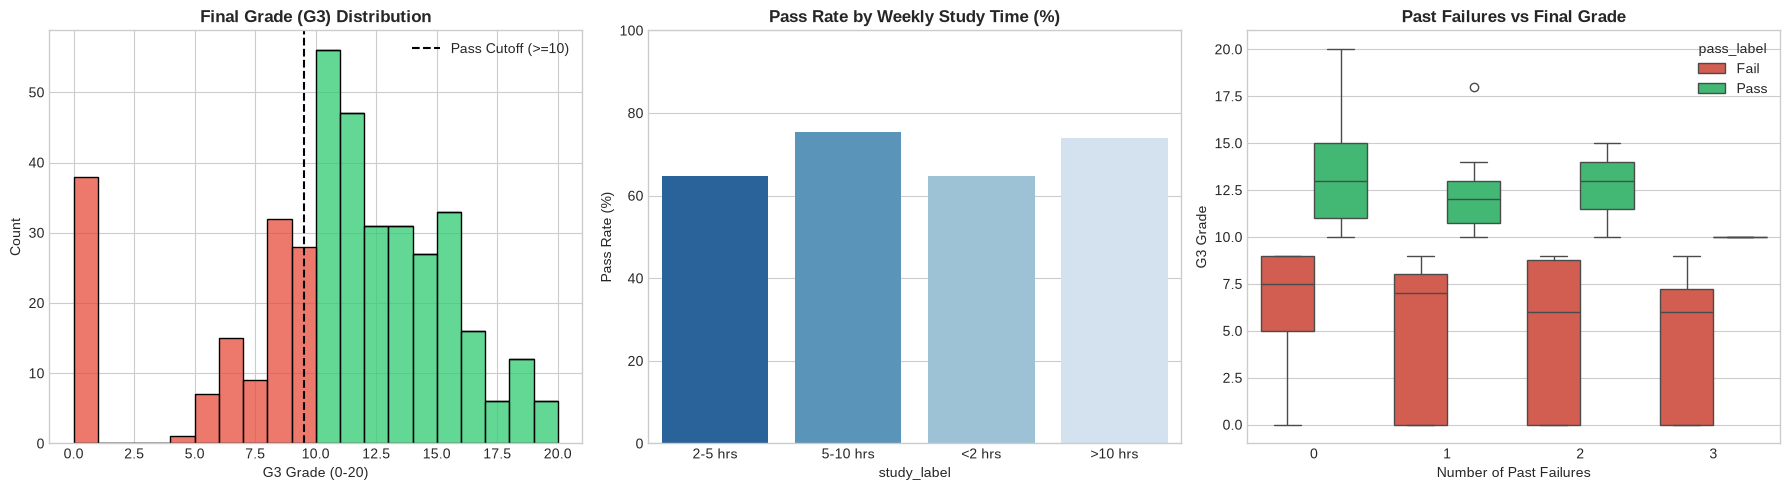

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Final grade distribution
sns.histplot(data=df, x='G3', hue='pass_label', multiple='stack', bins=20, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].axvline(9.5, color='black', linestyle='--', label='Pass Cutoff (>=10)')
axes[0].set_title("Final Grade (G3) Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("G3 Grade (0-20)")
axes[0].legend()

# 2. Study time vs. Pass rate
study_map = {1: '<2 hrs', 2: '2-5 hrs', 3: '5-10 hrs', 4: '>10 hrs'}
df['study_label'] = df['studytime'].map(study_map)
study_pass = df.groupby('study_label')['passed'].mean() * 100
sns.barplot(x=study_pass.index, y=study_pass.values, ax=axes[1], palette='Blues_r')
axes[1].set_title("Pass Rate by Weekly Study Time (%)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Pass Rate (%)")
axes[1].set_ylim(0, 100)

# 3. Past class failures vs. Final Grade
sns.boxplot(data=df, x='failures', y='G3', hue='pass_label', ax=axes[2], palette=['#e74c3c', '#2ecc71'])
axes[2].set_title("Past Failures vs Final Grade", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Past Failures")
axes[2].set_ylabel("G3 Grade")

plt.tight_layout()
plt.show()


## 5. Feature Engineering, Encoding, Scaling & Splitting
- Separate features $X$ and target $y$
- Standardize numeric features using `StandardScaler` (critical for KNN distance metrics and GaussianNB)
- Encode categorical features using `OneHotEncoder(drop='first')`
- Split into **Train (80%)** and **Test (20%)** sets with `stratify=y` to preserve the Pass/Fail balance.


In [6]:
# Define features to exclude (target and labels)
cols_to_exclude = {'G3', 'passed', 'pass_label', 'study_label'}

# Identify numeric and categorical columns
numeric_cols = [c for c in df.columns if c not in cols_to_exclude and pd.api.types.is_numeric_dtype(df[c])]
categorical_cols = [c for c in df.columns if c not in cols_to_exclude and not pd.api.types.is_numeric_dtype(df[c])]

print(f"Numeric features ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")

# Construct ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

X_raw = df[numeric_cols + categorical_cols]
y = df['passed'].values

X_transformed = preprocessor.fit_transform(X_raw)

# Get output feature names
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
feature_names = numeric_cols + encoded_cat_names

print(f"\nTransformed feature matrix shape: {X_transformed.shape}")

# Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_transformed, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Numeric features (15): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
Categorical features (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Transformed feature matrix shape: (395, 41)
Train samples: 316, Test samples: 79


## 6. Model Training: Decision Tree, Naïve Bayes & KNN
We train each classifier on the training set:
1. **Decision Tree Classifier:** Recursive partitioning with `max_depth=5` to prevent overfitting.
2. **Gaussian Naïve Bayes:** Probabilistic classification via Bayes' Theorem.
3. **K-Nearest Neighbors (KNN):** Distance-based instance learning with $k=5$.


In [7]:
# 1. Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_split=2, random_state=42)
dt_model.fit(X_train, y_train)

# 2. Gaussian Naïve Bayes Classifier
nb_model = GaussianNB(var_smoothing=1e-9)
nb_model.fit(X_train, y_train)

# 3. K-Nearest Neighbors Classifier
knn_model = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='minkowski')
knn_model.fit(X_train, y_train)

print("✅ All 3 models trained successfully!")


✅ All 3 models trained successfully!


## 7. Model Evaluation & Comparison
Evaluate all models on the holdout test set using:
- **Accuracy:** Overall proportion of correct predictions
- **Precision:** $\frac{TP}{TP + FP}$ (Accuracy of positive predictions)
- **Recall:** $\frac{TP}{TP + FN}$ (Ability to detect all passing students)
- **F1-Score:** Harmonic mean of Precision and Recall
- **Confusion Matrix:** Breakdown of True/False Positives/Negatives


In [12]:
from IPython.display import display
models = {
    "Decision Tree": dt_model,
    "Naïve Bayes": nb_model,
    "K-Nearest Neighbors": knn_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

# Add Majority Vote Ensemble
preds_matrix = np.array([predictions["Decision Tree"], predictions["Naïve Bayes"], predictions["K-Nearest Neighbors"]])
majority_vote_preds = (np.sum(preds_matrix, axis=0) >= 2).astype(int)
predictions["Majority Vote"] = majority_vote_preds

results.append({
    "Model": "Majority Vote (Ensemble)",
    "Accuracy (%)": round(accuracy_score(y_test, majority_vote_preds) * 100, 2),
    "Precision (%)": round(precision_score(y_test, majority_vote_preds, zero_division=0) * 100, 2),
    "Recall (%)": round(recall_score(y_test, majority_vote_preds, zero_division=0) * 100, 2),
    "F1-Score (%)": round(f1_score(y_test, majority_vote_preds, zero_division=0) * 100, 2)
})

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Decision Tree,86.08,97.73,81.13,88.66
1,Naïve Bayes,81.01,88.00,83.02,85.44
2,K-Nearest Neighbors,75.95,79.31,86.79,82.88
3,Majority Vote (Ensemble),86.08,92.00,86.79,89.32


### 7.1 Confusion Matrices Visualization

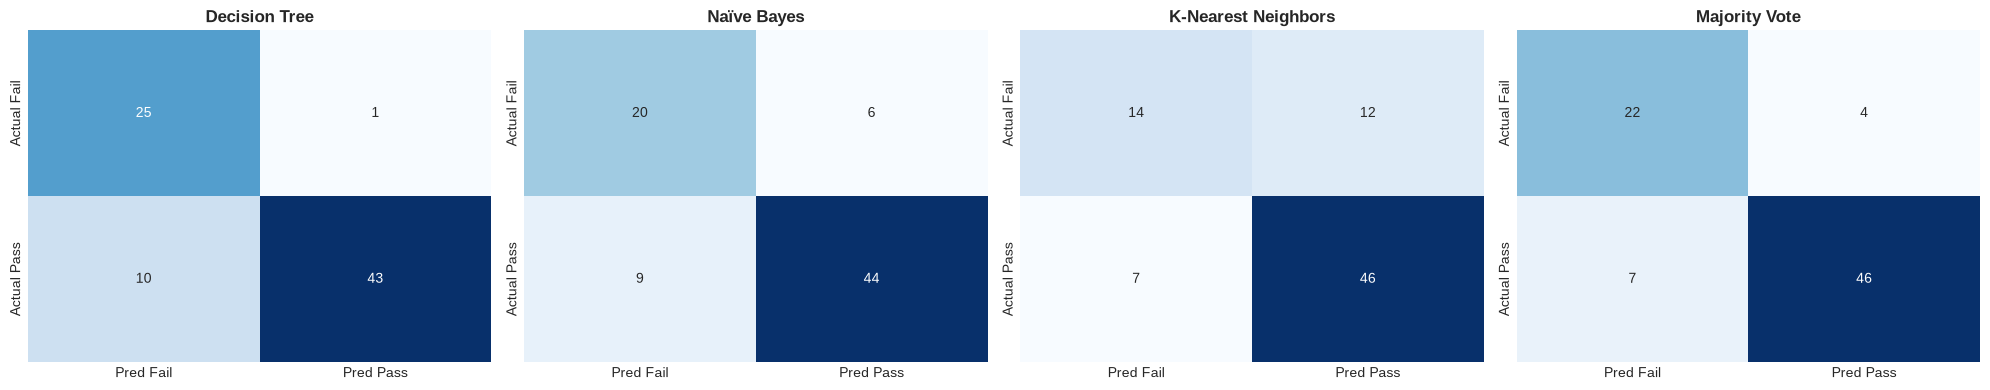

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
labels = ["Fail (0)", "Pass (1)"]

for ax, (name, y_p) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=["Pred Fail", "Pred Pass"], yticklabels=["Actual Fail", "Actual Pass"])
    ax.set_title(f"{name}", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Decision Tree Feature Importance
Analyze which features had the highest influence in splitting decisions.


/tmp/ipykernel_15289/1872391586.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df.head(10), x='Importance', y='Feature', palette='viridis')


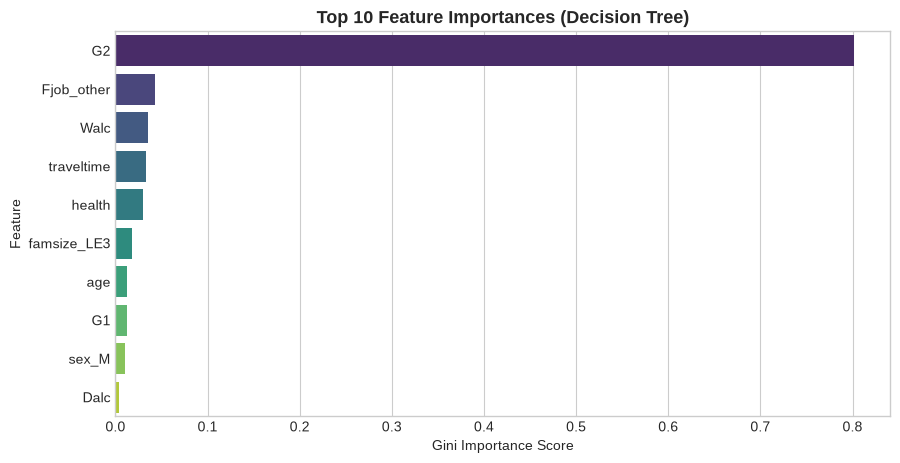

In [14]:
importances = dt_model.feature_importances_
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=fi_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("Top 10 Feature Importances (Decision Tree)", fontsize=13, fontweight='bold')
plt.xlabel("Gini Importance Score")
plt.show()


## 9. Live Student Prediction Simulation
We test the trained models on a hypothetical student record to observe how each classifier votes.


In [15]:
# Create a test student record
sample_student_data = {
    'school': 'GP', 'sex': 'F', 'age': 17, 'address': 'U', 'famsize': 'GT3', 'Pstatus': 'T',
    'Medu': 4, 'Fedu': 3, 'Mjob': 'services', 'Fjob': 'services', 'reason': 'reputation',
    'guardian': 'mother', 'traveltime': 1, 'studytime': 3, 'failures': 0, 'schoolsup': 'no',
    'famsup': 'yes', 'paid': 'yes', 'activities': 'yes', 'nursery': 'yes', 'higher': 'yes',
    'internet': 'yes', 'romantic': 'no', 'famrel': 4, 'freetime': 3, 'goout': 2,
    'Dalc': 1, 'Walc': 1, 'health': 5, 'absences': 2, 'G1': 14, 'G2': 15
}

sample_df = pd.DataFrame([sample_student_data])
X_sample = preprocessor.transform(sample_df)

print("--- Single Student Prediction Results ---")
votes = []
for name, model in [("Decision Tree", dt_model), ("Naïve Bayes", nb_model), ("K-Nearest Neighbors", knn_model)]:
    pred = model.predict(X_sample)[0]
    votes.append(pred)
    label = "PASS" if pred == 1 else "FAIL"
    prob = model.predict_proba(X_sample)[0][1] if hasattr(model, 'predict_proba') else None
    prob_str = f" (Pass Confidence: {prob*100:.1f}%)" if prob is not None else ""
    print(f"• {name}: {label}{prob_str}")

majority_verdict = "PASS" if sum(votes) >= 2 else "FAIL"
print(f"\n🗳️ Majority-Vote Verdict: {majority_verdict} ({sum(votes)}/3 votes)")


--- Single Student Prediction Results ---
• Decision Tree: PASS (Pass Confidence: 100.0%)
• Naïve Bayes: PASS (Pass Confidence: 100.0%)
• K-Nearest Neighbors: PASS (Pass Confidence: 100.0%)

🗳️ Majority-Vote Verdict: PASS (3/3 votes)


## 10. Summary & Conclusions
- **Decision Tree:** Provides clear interpretability through feature splits (particularly G2, G1, and past failures).
- **Naïve Bayes:** Offers quick training and probabilistic confidence scores, assuming feature independence.
- **K-Nearest Neighbors:** Classifies students based on proximity to similar past students in normalized feature space.
- **Majority Vote:** Combines all three models to minimize individual model error and provide a reliable consensus.

The Streamlit web application (`app.py`) provides an interactive interface for instructors, students, and counselors to experiment with these models in real time.
